# Coeliac mutagenesis analysis

In this notebook we try to recreate the results of the paper that the α1 peptide is a stronger binder than the ω1 peptide and that disrupting the 'WD' motif in the CDR3β will reduce binding to both epitopes.

In [1]:
import anarci
import IPython.display as ipy_display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns

In [2]:
SIGNIFICANCE_LEVEL = 0.05

In [3]:
sequences = pd.read_csv('../data/interim/sequences_coeliac_mutations.csv', index_col='id')

In [4]:
sequences['wd_motif'] = sequences['cdr3_beta'].map(
    lambda cdr3_beta: 'Contains WD motif' if 'WD' in cdr3_beta else 'Does not contain WD motif'
)

In [5]:
sequences['original'] = sequences.index.map(lambda id_: 'original' in id_)

cdr3_alpha = sequences[sequences['original']]['cdr3_alpha'].unique()[0]
sequences_beta_only_mutations = sequences[sequences['cdr3_alpha'] == cdr3_alpha].copy()

In [6]:
def find_mutation_location(new_chain: str, original: str) -> tuple[int, str]:
    numbering, _ = anarci.number(new_chain)

    original_idx = 0
    for (seq_id, insert_code), residue in numbering:
        if residue == '-':
            continue

        if residue != original[original_idx]:
            return seq_id, insert_code

        original_idx += 1

    msg = f'No mutation found in {new_chain}'
    raise ValueError(msg)


sequences_beta_only_mutations[['mutation_seq_id', 'mutation_insert_code_id']] = None

sequences_beta_only_mutations.loc[
    (sequences_beta_only_mutations['pmhc_calls'] == 'a1') & ~sequences_beta_only_mutations['original'],
    ['mutation_seq_id', 'mutation_insert_code_id'],
] = (
    sequences_beta_only_mutations.loc[
        (sequences_beta_only_mutations['pmhc_calls'] == 'a1') & ~sequences_beta_only_mutations['original'],
        'tcr_beta_chain',
    ]
    .map(
        lambda tcr_beta_chain: find_mutation_location(
            tcr_beta_chain, sequences_beta_only_mutations.loc['coeliac_a1_mut_original', 'tcr_beta_chain']
        )
    )
    .apply(pd.Series)
    .to_numpy()
)

sequences_beta_only_mutations.loc[
    (sequences_beta_only_mutations['pmhc_calls'] == 'w1') & ~sequences_beta_only_mutations['original'],
    ['mutation_seq_id', 'mutation_insert_code_id'],
] = (
    sequences_beta_only_mutations.loc[
        (sequences_beta_only_mutations['pmhc_calls'] == 'w1') & ~sequences_beta_only_mutations['original'],
        'tcr_beta_chain',
    ]
    .map(
        lambda tcr_beta_chain: find_mutation_location(
            tcr_beta_chain, sequences_beta_only_mutations.loc['coeliac_w1_mut_original', 'tcr_beta_chain']
        )
    )
    .apply(pd.Series)
    .to_numpy()
)

In [7]:
true_interactions = pd.read_csv('../data/processed/coeliac_structure_interactions.csv')

In [8]:
true_a1_interactions_summary = (
    true_interactions.query("name == 'DQ2_5a1_572G2_DECAB'")[
        ['type', 'domain', 'original_numbering', 'protein_residue', 'ligand_number', 'ligand_residue', 'distance']
    ]
    .sort_values('original_numbering')
    .reset_index(drop=True)
)
true_a1_interactions_summary['ligand_number'] = true_a1_interactions_summary['ligand_number'] + 1

true_w1_interactions_summary = (
    true_interactions.query("name == 'DQ2_5w1_572G2_DECAB'")[
        ['type', 'domain', 'original_numbering', 'protein_residue', 'ligand_number', 'ligand_residue', 'distance']
    ]
    .sort_values(['original_numbering', 'ligand_number'])
    .reset_index(drop=True)
)
true_w1_interactions_summary['ligand_number'] = true_w1_interactions_summary['ligand_number'] + 1

In [9]:
sequences_beta_only_mutations['disrupts_interaction'] = None

sequences_beta_only_mutations.loc[sequences_beta_only_mutations['pmhc_calls'] == 'a1', 'disrupts_interaction'] = (
    sequences_beta_only_mutations.loc[sequences_beta_only_mutations['pmhc_calls'] == 'a1', 'mutation_seq_id'].map(
        lambda mutation_seq_id: mutation_seq_id in true_a1_interactions_summary['original_numbering'].tolist()
    )
)
sequences_beta_only_mutations.loc[sequences_beta_only_mutations['pmhc_calls'] == 'w1', 'disrupts_interaction'] = (
    sequences_beta_only_mutations.loc[sequences_beta_only_mutations['pmhc_calls'] == 'w1', 'mutation_seq_id'].map(
        lambda mutation_seq_id: mutation_seq_id in true_w1_interactions_summary['original_numbering'].tolist()
    )
)
sequences_beta_only_mutations['disrupts_interaction'] = sequences_beta_only_mutations['disrupts_interaction'].astype(
    bool
)

In [10]:
confidence_scores = pd.read_csv('../data/interim/confidence_scores_af3_af3_tcrmodel2_coeliac_mutations.csv')

In [11]:
confidence_scores = confidence_scores.merge(
    sequences_beta_only_mutations, how='inner', left_on='name', right_index=True
)

In [12]:
binding_scores = pd.read_csv('../data/processed/af3_af3_tcrmodel2_coeliac_mutations_pae_aggregator_predictions.csv')
binding_scores['prediction'] = binding_scores[
    ['prediction_1', 'prediction_2', 'prediction_3', 'prediction_4', 'prediction_5']
].apply('median', axis=1)

In [13]:
binding_scores = binding_scores.merge(sequences_beta_only_mutations, how='inner', left_on='name', right_index=True)

## Structure prediction quality

In [14]:
CAPRI_ACCEPTABLE_CUTOFF = 0.23
CAPRI_MEDIUM_CUTOFF = 0.49
CAPRI_HIGH_CUTOFF = 0.80

In [15]:
dockq_scores = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_dockq_coeliac.csv')
dockq_scores[['name', 'reference_structure']] = dockq_scores['name'].str.split('-').apply(pd.Series)

In [16]:
dockq_scores = dockq_scores.merge(confidence_scores, how='inner', on=['name', 'seed', 'sample'])

In [17]:
dockq_scores['top_rank'] = False
dockq_scores.loc[dockq_scores.groupby('name')['ranking_score'].idxmax(), 'top_rank'] = True

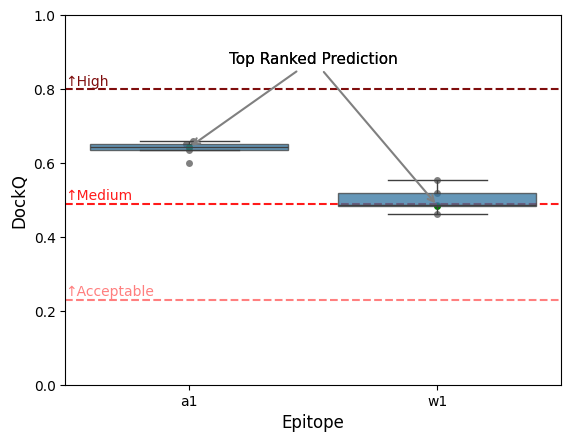

In [18]:
fig, ax = plt.subplots(1, 1)

for label, cutoff, colour in (
    ('↑Acceptable', CAPRI_ACCEPTABLE_CUTOFF, '#ff7f7f'),
    ('↑Medium', CAPRI_MEDIUM_CUTOFF, '#ff1a1a'),
    ('↑High', CAPRI_HIGH_CUTOFF, '#7f0d0d'),
):
    ax.text(-0.5, cutoff + 0.01, label, color=colour)
    ax.axhline(cutoff, linestyle='dashed', color=colour)

sns.boxplot(
    dockq_scores,
    x='pmhc_calls',
    y='DockQ',
    color='tab:blue',
    showfliers=False,
    boxprops={'alpha': 0.75},
    zorder=2,
    ax=ax,
)
sns.swarmplot(dockq_scores.query('not top_rank'), y='DockQ', x='pmhc_calls', color='grey', zorder=1, ax=ax)
sns.swarmplot(dockq_scores.query('top_rank'), y='DockQ', x='pmhc_calls', color='green', zorder=1, ax=ax)

for _, pmhc_calls, dockq in dockq_scores.query('top_rank')[['pmhc_calls', 'DockQ']].itertuples():
    ax.annotate(
        'Top Ranked Prediction',
        xy=(pmhc_calls, dockq),
        xycoords='data',
        xytext=(0.50, 0.90),
        textcoords='axes fraction',
        va='top',
        ha='center',
        arrowprops={'arrowstyle': '->', 'color': 'gray', 'lw': 1.5},
        fontsize=11,
    )

ax.set_ylim([0.0, 1.0])

ax.set_ylabel(ax.get_ylabel(), fontsize=12)
ax.set_xlabel('Epitope', fontsize=12)

plt.savefig('../report/figures/coeliac_tcrs_dockq.svg')
plt.show()

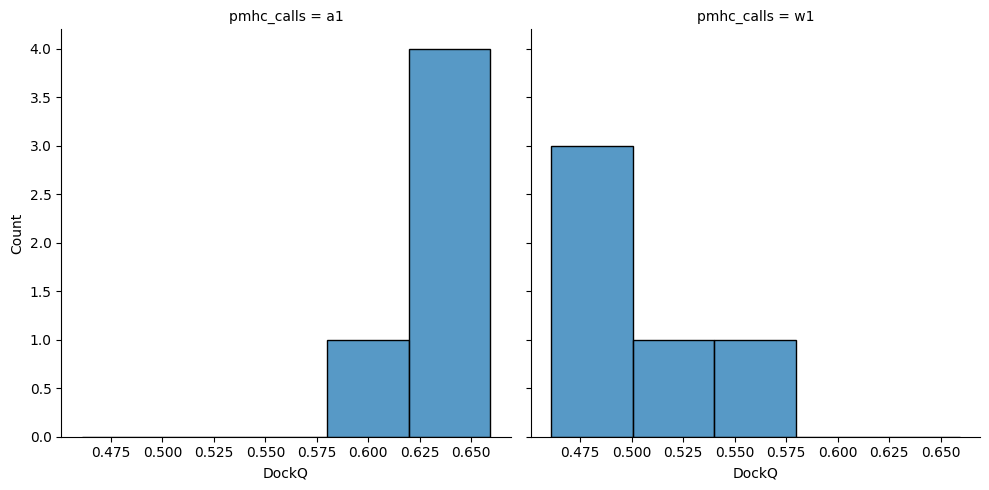

In [19]:
sns.displot(dockq_scores, col='pmhc_calls', x='DockQ', kind='hist')
plt.show()

In [20]:
pg.mwu(
    dockq_scores[dockq_scores['pmhc_calls'] == 'a1']['DockQ'],
    dockq_scores[dockq_scores['pmhc_calls'] == 'w1']['DockQ'],
    alternative='two-sided',
)

,U-val,alternative,p-val,RBC,CLES
MWU,25.0,two-sided,0.007937,1.0,1.0


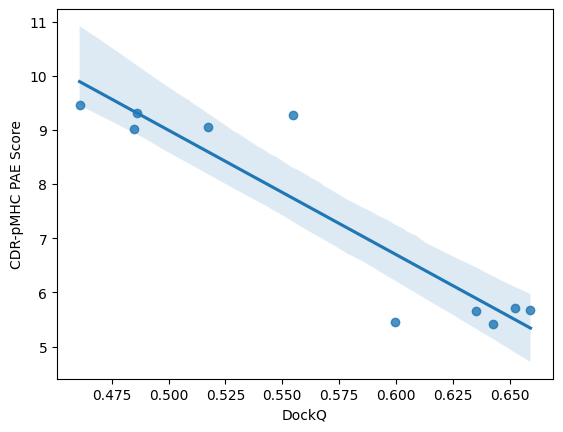

In [21]:
ax = sns.regplot(dockq_scores, x='DockQ', y='cdr_pmhc_pae_score')

ax.set_xlabel('DockQ')
ax.set_ylabel('CDR-pMHC PAE Score')

plt.savefig('../report/figures/coeliac_corr_confidence_dockq.svg')
plt.show()

In [22]:
result = pg.corr(dockq_scores['DockQ'], dockq_scores['cdr_pmhc_pae_score'], alternative='less')

print(f"R^2 = {result.iloc[0]['r'] ** 2:.2f}")
result

R^2 = 0.86


,n,r,CI95%,p-val,BF10,power
pearson,10,-0.92618,"[-1.0, -0.77]",0.000059,418.617,0.997578


## Epitope baseline binding score

In [23]:
binding_scores.value_counts(['pmhc_calls', 'wd_motif']).sort_index()

pmhc_calls  wd_motif                 
a1          Contains WD motif            35
            Does not contain WD motif    10
w1          Contains WD motif            35
            Does not contain WD motif    10
Name: count, dtype: int64

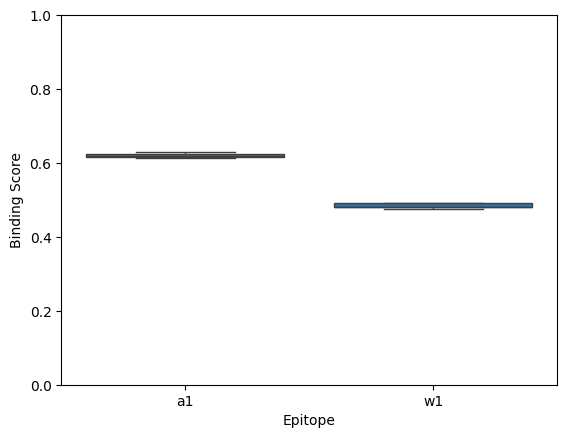

In [ ]:
ax = sns.boxplot(binding_scores.query('original'), x='pmhc_calls', y='prediction')

ax.set_xlabel('Epitope')
ax.set_ylabel('Binding Score')
ax.set_ylim([0.0, 1.0])

plt.savefig('../report/figures/coeliac_epitope_affinity_boxplot.svg')
plt.show()

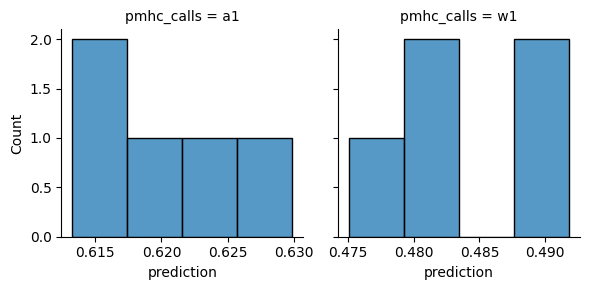

In [25]:
grid = sns.FacetGrid(binding_scores.query('original'), col='pmhc_calls', sharex=False)
grid.map_dataframe(sns.histplot, x='prediction')

plt.show()

In [26]:
result = pg.mwu(
    binding_scores.query("original and pmhc_calls == 'a1'")['prediction'],
    binding_scores.query("original and pmhc_calls == 'w1'")['prediction'],
    alternative='greater',
)
result['significant'] = result['p-val'] < SIGNIFICANCE_LEVEL

result

,U-val,alternative,p-val,RBC,CLES,significant
MWU,25.0,greater,0.003968,1.0,1.0,True


## Mutagenesis analysis

In [27]:
binding_scores_mutations = binding_scores.query('not original')

### WD-motif

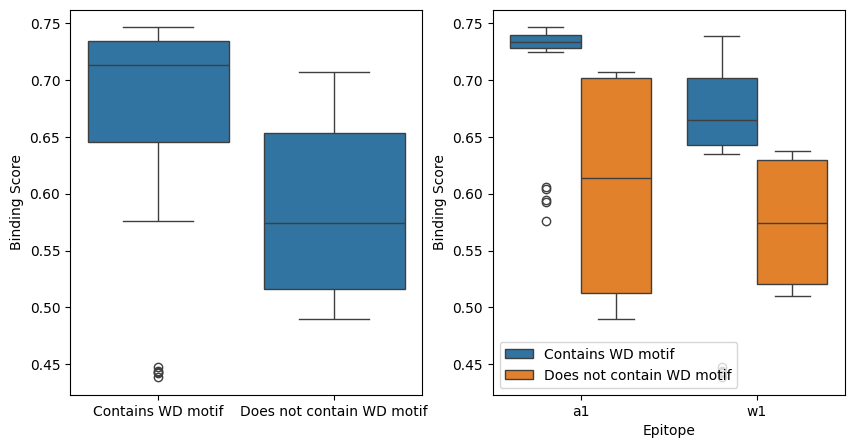

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.boxplot(binding_scores_mutations, x='wd_motif', y='prediction', ax=axes[0])

axes[0].set_ylabel('Binding Score')
axes[0].set_xlabel('')

sns.boxplot(binding_scores_mutations, x='pmhc_calls', y='prediction', hue='wd_motif', ax=axes[1])

axes[1].set_ylabel('Binding Score')
axes[1].set_xlabel('Epitope')

axes[1].legend(title='', loc='lower left')

plt.savefig('../report/figures/coeliac_mutations_boxplot.svg')
plt.show()

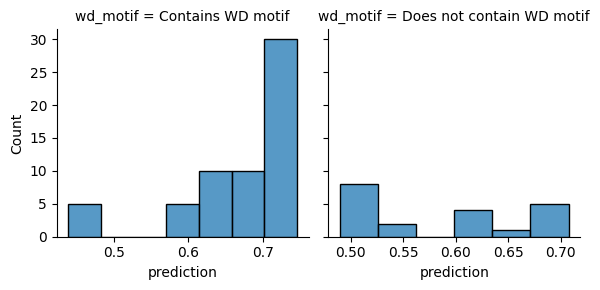

In [29]:
grid = sns.FacetGrid(binding_scores_mutations, col='wd_motif', sharex=False)
grid.map_dataframe(sns.histplot, x='prediction')

plt.show()

In [30]:
result = pg.mwu(
    binding_scores_mutations.query("wd_motif == 'Contains WD motif'")['prediction'],
    binding_scores_mutations.query("wd_motif == 'Does not contain WD motif'")['prediction'],
    alternative='greater',
)
result['significant'] = result['p-val'] < SIGNIFICANCE_LEVEL

result

,U-val,alternative,p-val,RBC,CLES,significant
MWU,958.0,greater,0.000036,0.596667,0.798333,True


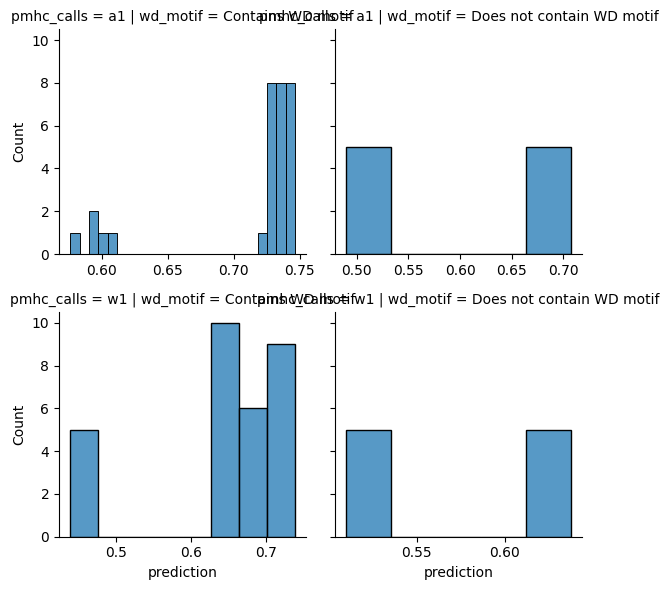

In [31]:
grid = sns.FacetGrid(binding_scores_mutations, row='pmhc_calls', col='wd_motif', sharex=False)
grid.map_dataframe(sns.histplot, x='prediction')

plt.show()

In [32]:
result = pg.anova(binding_scores_mutations, dv='prediction', between=['pmhc_calls', 'wd_motif'])
result['significant'] = result['p-unc'] < SIGNIFICANCE_LEVEL

result

,Source,SS,DF,MS,F,p-unc,np2,significant
0,pmhc_calls,0.075449,1.0,0.075449,12.154463,0.000817,0.137877,True
1,wd_motif,0.111341,1.0,0.111341,17.936659,0.000063,0.190944,True
2,pmhc_calls * wd_motif,0.005927,1.0,0.005927,0.954751,0.331613,0.012407,False
3,Residual,0.471768,76.0,0.006207,NaN,NaN,NaN,False


In [33]:
results = []

for pmhc_calls, epitope_group in binding_scores_mutations.groupby('pmhc_calls'):
    result = pg.ttest(
        epitope_group.query("wd_motif == 'Contains WD motif'")['prediction'],
        epitope_group.query("wd_motif == 'Does not contain WD motif'")['prediction'],
        alternative='greater',
    )
    result['epitope_name'] = pmhc_calls

    results.append(result)

results = pd.concat(results)
results = results.set_index('epitope_name')
results['significant'] = results['p-val'] < (SIGNIFICANCE_LEVEL / len(results))

results

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power,significant
epitope_name,,,,,,,,,
a1,3.131482,10.710363,greater,0.004924,"[0.05, inf]",1.545878,22.949,0.993993,True
w1,2.625269,25.978752,greater,0.007158,"[0.02, inf]",0.754806,8.459,0.649972,True


### All interactions

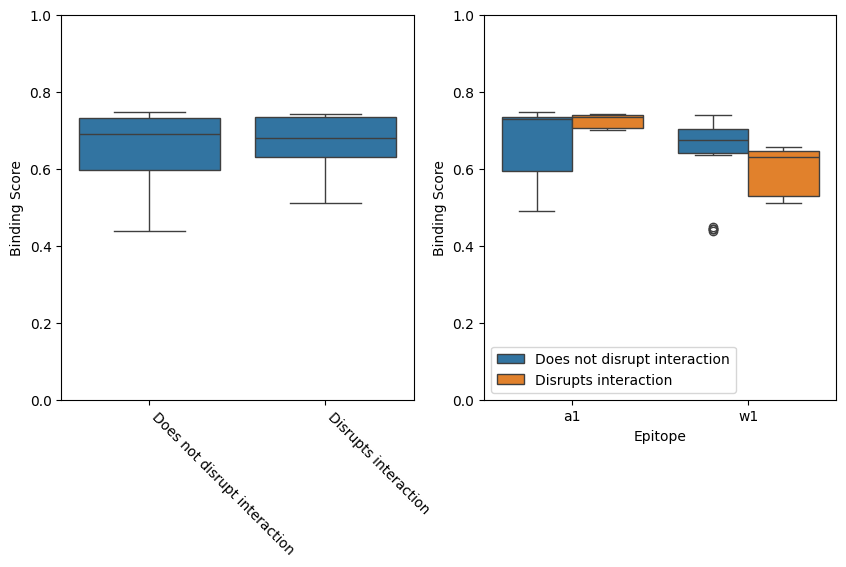

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.boxplot(binding_scores_mutations, x='disrupts_interaction', y='prediction', ax=axes[0])

axes[0].set_ylabel('Binding Score')
axes[0].set_ylim(0.0, 1.0)

axes[0].set_xlabel('')
axes[0].set_xticks(axes[0].get_xticks())
axes[0].set_xticklabels(
    [
        {'True': 'Disrupts interaction', 'False': 'Does not disrupt interaction'}[label.get_text()]
        for label in axes[0].get_xticklabels()
    ],
    rotation=-45,
    ha='left',
)

sns.boxplot(binding_scores_mutations, x='pmhc_calls', y='prediction', hue='disrupts_interaction', ax=axes[1])

axes[1].set_ylabel('Binding Score')
axes[1].set_ylim(0.0, 1.0)

axes[1].set_xlabel('Epitope')

handles, labels = axes[1].get_legend_handles_labels()
axes[1].legend(
    handles,
    [{'True': 'Disrupts interaction', 'False': 'Does not disrupt interaction'}[label] for label in labels],
    title='',
    loc='lower left',
)

plt.savefig('../report/figures/coeliac_interaction_mutations_boxplot.svg')
plt.show()

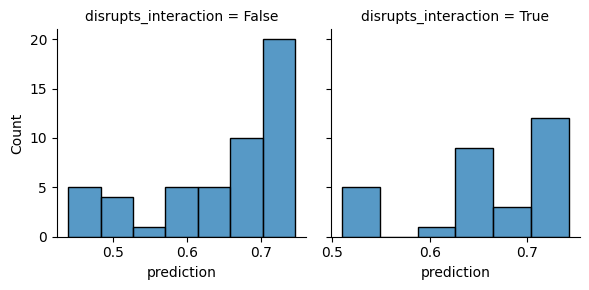

In [35]:
grid = sns.FacetGrid(binding_scores_mutations, col='disrupts_interaction', sharex=False)
grid.map_dataframe(sns.histplot, x='prediction')

plt.show()

In [36]:
result = pg.mwu(
    binding_scores_mutations.loc[~binding_scores_mutations['disrupts_interaction'], 'prediction'],
    binding_scores_mutations.loc[binding_scores_mutations['disrupts_interaction'], 'prediction'],
    alternative='greater',
)
result['significant'] = result['p-val'] < SIGNIFICANCE_LEVEL

result

,U-val,alternative,p-val,RBC,CLES,significant
MWU,703.0,greater,0.681558,-0.062667,0.468667,False


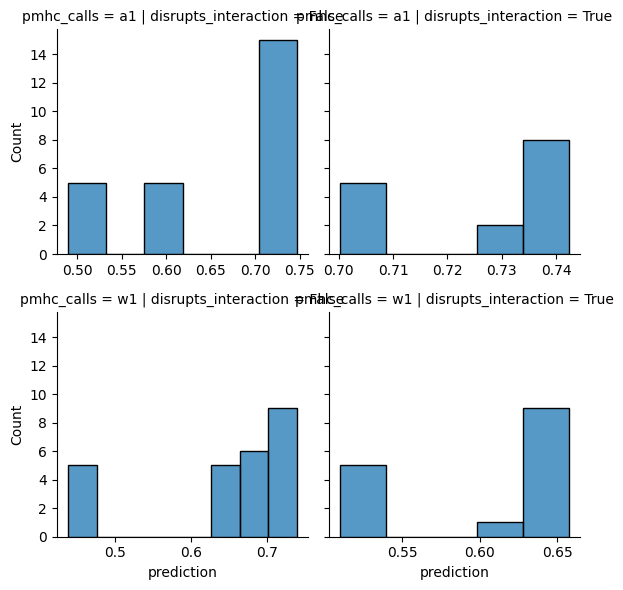

In [37]:
grid = sns.FacetGrid(binding_scores_mutations, row='pmhc_calls', col='disrupts_interaction', sharex=False)
grid.map_dataframe(sns.histplot, x='prediction')

plt.show()

In [38]:
result = pg.anova(binding_scores_mutations, dv='prediction', between=['pmhc_calls', 'disrupts_interaction'])
result['significant'] = result['p-unc'] < SIGNIFICANCE_LEVEL

result

,Source,SS,DF,MS,F,p-unc,np2,significant
0,pmhc_calls,0.075449,1.0,0.075449,10.709175,0.001605,0.123507,True
1,disrupts_interaction,0.003008,1.0,0.003008,0.427026,0.515424,0.005587,False
2,pmhc_calls * disrupts_interaction,0.050591,1.0,0.050591,7.180843,0.009030,0.086328,True
3,Residual,0.535437,76.0,0.007045,NaN,NaN,NaN,False


In [39]:
results = []

for pmhc_calls, epitope_group in binding_scores_mutations.groupby('pmhc_calls'):
    result = pg.ttest(
        epitope_group.query('not disrupts_interaction')['prediction'],
        epitope_group.query('disrupts_interaction')['prediction'],
        alternative='greater',
    )
    result['epitope_name'] = pmhc_calls

    results.append(result)

results = pd.concat(results)
results = results.set_index('epitope_name')
results['significant'] = results['p-val'] < (SIGNIFICANCE_LEVEL / len(results))

results

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power,significant
epitope_name,,,,,,,,,
a1,-3.287661,26.547213,greater,0.998577,"[-0.1, inf]",0.841607,0.03,0.000015,False
w1,1.515615,37.940044,greater,0.068952,"[-0.0, inf]",0.433828,1.545,0.366854,False


## Correlation between confidence score and SPR

In [40]:
affinities = {
    'coeliac_a1_mut_original': 6.1,
    'coeliac_a1_mut_10': 8.2,
    'coeliac_a1_mut_14': np.inf,
    'coeliac_a1_mut_15': 280,
    'coeliac_w1_mut_original': 37.8,
    'coeliac_w1_mut_10': 41.2,
    'coeliac_w1_mut_14': np.inf,
    'coeliac_w1_mut_15': np.inf,
}
binding_scores['affinity'] = binding_scores['name'].map(affinities)

Scaling affinity by $$\frac{x_{min}}{x}$$

In [41]:
binding_scores['affinity_norm'] = binding_scores['affinity'].min() / binding_scores['affinity']

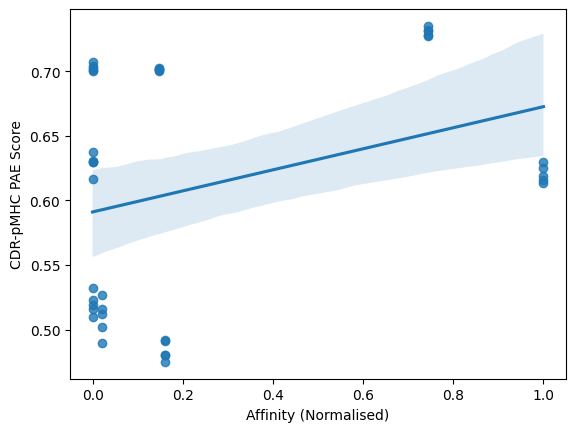

In [42]:
ax = sns.regplot(binding_scores, x='affinity_norm', y='prediction')

ax.set_xlabel('Affinity (Normalised)')
ax.set_ylabel('CDR-pMHC PAE Score')

plt.savefig('../report/figures/coeliac_mutations_corr_affinity_confidence.svg')
plt.show()

In [43]:
result = pg.corr(binding_scores['affinity_norm'], binding_scores['prediction'], alternative='greater')

print(f"R^2 = {result.iloc[0]['r'] ** 2:.2f}")
result

R^2 = 0.11


,n,r,CI95%,p-val,BF10,power
pearson,40,0.325862,"[0.07, 1.0]",0.020086,2.937,0.66967


## Interactions

In [44]:
predicted_interactions = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_interactions_coeliac_mutations.csv')
predicted_interactions = predicted_interactions.merge(
    sequences_beta_only_mutations, how='right', left_on='name', right_index=True
)

In [45]:
def calculate_interaction_accuracy(group: pd.DataFrame, true_interactions: pd.DataFrame) -> float:
    group = group.merge(
        true_interactions[
            ['type', 'domain', 'original_numbering', 'protein_residue', 'ligand_number', 'ligand_residue']
        ],
        how='outer',
        indicator=True,
    )
    classification = group['_merge'].map({'both': 'TP', 'left_only': 'FP', 'right_only': 'FN'})
    classification_counts = classification.value_counts()

    return (classification_counts['TP'] / classification_counts.sum()) * 100

### α1 epitope

In [46]:
true_a1_interactions_summary

,type,domain,original_numbering,protein_residue,ligand_number,ligand_residue,distance
0,hydrophobic,VB,37,ARG,9,PRO,3.612334
1,hydrophobic,VB,108,LEU,9,PRO,3.775657
2,hydrophobic,VB,109,VAL,9,PRO,3.919943
3,hydrophobic,VB,112,TRP,6,PRO,3.813673


In [47]:
original_a1_interactions = predicted_interactions.query("original and pmhc_calls == 'a1'")

num_predictions = len(original_a1_interactions.drop_duplicates(['name', 'seed', 'sample']))

original_a1_interactions_summary = original_a1_interactions.value_counts(
    ['type', 'domain', 'original_numbering', 'protein_residue', 'ligand_number', 'ligand_residue']
)
original_a1_interactions_summary = (original_a1_interactions_summary / num_predictions) * 100
original_a1_interactions_summary.name = 'captured_percent'

original_a1_interactions_summary = original_a1_interactions_summary.reset_index()
original_a1_interactions_summary = original_a1_interactions_summary.sort_values('original_numbering')

original_a1_interactions_summary = original_a1_interactions_summary.merge(
    true_a1_interactions_summary[
        ['type', 'domain', 'original_numbering', 'protein_residue', 'ligand_number', 'ligand_residue']
    ],
    how='outer',
    indicator=True,
)
original_a1_interactions_summary['captured_percent'] = original_a1_interactions_summary['captured_percent'].fillna(0.0)

merge_mask = original_a1_interactions_summary['_merge'].isin(('both', 'right_only'))
original_a1_interactions_summary = original_a1_interactions_summary.drop('_merge', axis='columns')

original_a1_interactions_summary.style.apply(
    lambda row, merge_mask=merge_mask: (['font-weight: bold'] * len(row) if merge_mask[row.name] else [''] * len(row)),
    axis=1,
)

,type,domain,original_numbering,protein_residue,ligand_number,ligand_residue,captured_percent
0,hydrophobic,VB,37,ARG,9,PRO,0.000000
1,hydrophobic,VB,108,LEU,9,PRO,40.000000
2,hydrophobic,VB,109,VAL,9,PRO,100.000000
3,hydrophobic,VB,112,TRP,6,PRO,80.000000


In [48]:
original_a1_interactions_accuray = original_a1_interactions.groupby(['seed', 'sample']).apply(
    calculate_interaction_accuracy, true_interactions=true_a1_interactions_summary, include_groups=False
)

print(
    f'Accuracy of recovering interactions in a1 epitope: {original_a1_interactions_accuray.mean():.2f}% '
    f'(± {original_a1_interactions_accuray.sem():.2f}%)'
)

Accuracy of recovering interactions in a1 epitope: 55.00% (± 9.35%)


In [49]:
mutant_a1_interactions = predicted_interactions.query("not original and pmhc_calls == 'a1'")

mutant_a1_interactions_summaries = {}
for motif_status, group in mutant_a1_interactions.groupby('wd_motif'):
    print(motif_status)
    num_predictions = len(group.drop_duplicates(['name', 'seed', 'sample']))

    group_summary = group.value_counts(
        ['type', 'domain', 'original_numbering', 'protein_residue', 'ligand_number', 'ligand_residue']
    )
    group_summary = (group_summary / num_predictions) * 100
    group_summary.name = 'captured_percent'

    group_summary = group_summary.reset_index()
    group_summary = group_summary.sort_values('original_numbering')

    group_summary = group_summary.merge(
        true_a1_interactions_summary[
            ['type', 'domain', 'original_numbering', 'protein_residue', 'ligand_number', 'ligand_residue']
        ],
        how='outer',
        indicator=True,
    )
    group_summary['captured_percent'] = group_summary['captured_percent'].fillna(0.0)

    merge_mask = group_summary['_merge'].isin(('both', 'right_only'))
    group_summary = group_summary.drop('_merge', axis='columns')

    ipy_display.display(
        group_summary.style.apply(
            lambda row, merge_mask=merge_mask: (
                ['font-weight: bold'] * len(row) if merge_mask[row.name] else [''] * len(row)
            ),
            axis=1,
        )
    )

    mutant_a1_interactions_summaries[motif_status] = group_summary

Contains WD motif


,type,domain,original_numbering,protein_residue,ligand_number,ligand_residue,captured_percent
0,hbond,VA,109,GLY,1,GLN,10.000000
1,hbond,VB,37,ARG,10,TYR,13.333333
2,hbond,VB,37,ARG,11,PRO,13.333333
3,hydrophobic,VB,37,ARG,9,PRO,6.666667
4,hydrophobic,VB,57,PHE,9,PRO,30.000000
5,hydrophobic,VB,108,LEU,8,LEU,33.333333
6,hydrophobic,VB,108,LEU,9,PRO,20.000000
7,hydrophobic,VB,109,ALA,8,LEU,16.666667
8,hydrophobic,VB,109,VAL,6,PRO,13.333333
9,hydrophobic,VB,109,VAL,8,LEU,30.000000


Does not contain WD motif


,type,domain,original_numbering,protein_residue,ligand_number,ligand_residue,captured_percent
0,hydrophobic,VA,37,ASN,3,PHE,20.000000
1,hydrophobic,VB,37,ARG,9,PRO,0.000000
2,hydrophobic,VB,108,LEU,8,LEU,50.000000
3,hydrophobic,VB,108,LEU,9,PRO,30.000000
4,hydrophobic,VB,109,VAL,9,PRO,70.000000
5,hydrophobic,VB,112,ALA,6,PRO,30.000000
6,hydrophobic,VB,112,TRP,6,PRO,70.000000


In [50]:
mutant_a1_interactions_comparison = (
    mutant_a1_interactions_summaries['Contains WD motif']
    .merge(
        mutant_a1_interactions_summaries['Does not contain WD motif'],
        on=['type', 'domain', 'original_numbering', 'protein_residue', 'ligand_number', 'ligand_residue'],
        how='outer',
        suffixes=('_wd_motif', '_no_wd_motif'),
    )
    .fillna(0.0)
    .sort_values(['domain', 'original_numbering', 'ligand_number'])
    .reset_index(drop=True)
)

with np.errstate(all='ignore'):
    mutant_a1_interactions_comparison['captured_percent_difference'] = np.log2(
        mutant_a1_interactions_comparison['captured_percent_wd_motif']
    ) - np.log2(mutant_a1_interactions_comparison['captured_percent_no_wd_motif'])

mutant_a1_interactions_comparison = (
    mutant_a1_interactions_comparison.merge(
        true_a1_interactions_summary[[col for col in true_a1_interactions_summary.columns if col != 'distance']],
        how='outer',
        indicator=True,
    )
    .sort_values(['domain', 'original_numbering', 'ligand_number'])
    .reset_index(drop=True)
)

merge_mask = mutant_a1_interactions_comparison['_merge'].isin(('both', 'right_only'))
mutant_a1_interactions_comparison = mutant_a1_interactions_comparison.drop('_merge', axis='columns')

mutant_a1_interactions_comparison.style.apply(
    lambda row, merge_mask=merge_mask: (['font-weight: bold'] * len(row) if merge_mask[row.name] else [''] * len(row)),
    axis=1,
)

,type,domain,original_numbering,protein_residue,ligand_number,ligand_residue,captured_percent_wd_motif,captured_percent_no_wd_motif,captured_percent_difference
0,hydrophobic,VA,37,ASN,3,PHE,0.000000,20.000000,-inf
1,hbond,VA,109,GLY,1,GLN,10.000000,0.000000,inf
2,hydrophobic,VB,37,ARG,9,PRO,6.666667,0.000000,inf
3,hbond,VB,37,ARG,10,TYR,13.333333,0.000000,inf
4,hbond,VB,37,ARG,11,PRO,13.333333,0.000000,inf
5,saltbridge,VB,37,ARG,11,PRO,13.333333,0.000000,inf
6,hydrophobic,VB,57,PHE,9,PRO,30.000000,0.000000,inf
7,hydrophobic,VB,108,LEU,8,LEU,33.333333,50.000000,-0.584963
8,hydrophobic,VB,108,LEU,9,PRO,20.000000,30.000000,-0.584963
9,hydrophobic,VB,109,VAL,6,PRO,13.333333,0.000000,inf


### ω1 epitope

In [51]:
true_w1_interactions_summary

,type,domain,original_numbering,protein_residue,ligand_number,ligand_residue,distance
0,hydrophobic,VB,108,LEU,9,PRO,3.565586
1,hydrophobic,VB,112,TRP,4,PRO,3.546830
2,hydrophobic,VB,112,TRP,6,PRO,3.620198
3,hydrophobic,VB,113,ASP,3,PHE,3.955730


In [52]:
original_w1_interactions = predicted_interactions.query("original and pmhc_calls == 'w1'")

num_predictions = len(original_w1_interactions.drop_duplicates(['name', 'seed', 'sample']))

original_w1_interactions_summary = original_w1_interactions.value_counts(
    ['type', 'domain', 'original_numbering', 'protein_residue', 'ligand_number', 'ligand_residue']
)
original_w1_interactions_summary = (original_w1_interactions_summary / num_predictions) * 100
original_w1_interactions_summary.name = 'captured_percent'

original_w1_interactions_summary = original_w1_interactions_summary.reset_index()
original_w1_interactions_summary = original_w1_interactions_summary.sort_values('original_numbering')

original_w1_interactions_summary = original_w1_interactions_summary.merge(
    true_w1_interactions_summary[
        ['type', 'domain', 'original_numbering', 'protein_residue', 'ligand_number', 'ligand_residue']
    ],
    how='outer',
    indicator=True,
)

original_w1_interactions_summary['captured_percent'] = original_w1_interactions_summary['captured_percent'].fillna(0.0)

merge_mask = original_w1_interactions_summary['_merge'].isin(('both', 'right_only'))
original_w1_interactions_summary = original_w1_interactions_summary.drop('_merge', axis='columns')

original_w1_interactions_summary.style.apply(
    lambda row, merge_mask=merge_mask: (['font-weight: bold'] * len(row) if merge_mask[row.name] else [''] * len(row)),
    axis=1,
)

,type,domain,original_numbering,protein_residue,ligand_number,ligand_residue,captured_percent
0,hbond,VB,37,ARG,10,PHE,20.000000
1,hydrophobic,VB,108,LEU,9,PRO,0.000000
2,hydrophobic,VB,109,VAL,9,PRO,80.000000
3,hydrophobic,VB,112,TRP,4,PRO,0.000000
4,hydrophobic,VB,112,TRP,6,PRO,160.000000
5,hydrophobic,VB,113,ASP,3,PHE,0.000000


In [53]:
original_w1_interactions_accuracy = original_w1_interactions.groupby(['seed', 'sample']).apply(
    calculate_interaction_accuracy, true_interactions=true_w1_interactions_summary, include_groups=False
)

print(
    f'Accuracy of recovering interactions in w1 epitope: {original_w1_interactions_accuracy.mean():.2f}% '
    f'(± {original_w1_interactions_accuracy.sem():.2f}%)'
)

Accuracy of recovering interactions in w1 epitope: 28.05% (± 2.55%)


In [54]:
mutant_a1_interactions = predicted_interactions.query("not original and pmhc_calls == 'a1'")

mutant_a1_interactions_summaries = {}
for motif_status, group in mutant_a1_interactions.groupby('wd_motif'):
    print(motif_status)
    num_predictions = len(group.drop_duplicates(['name', 'seed', 'sample']))

    group_summary = group.value_counts(
        ['type', 'domain', 'original_numbering', 'protein_residue', 'ligand_number', 'ligand_residue']
    )
    group_summary = (group_summary / num_predictions) * 100
    group_summary.name = 'captured_percent'

    group_summary = group_summary.reset_index()
    group_summary = group_summary.sort_values('original_numbering')

    group_summary = (
        group_summary.merge(
            true_a1_interactions_summary[
                ['type', 'domain', 'original_numbering', 'protein_residue', 'ligand_number', 'ligand_residue']
            ],
            how='outer',
            indicator=True,
        )
        .sort_values(['domain', 'original_numbering', 'ligand_number'])
        .reset_index(drop=True)
    )

    group_summary['captured_percent'] = group_summary['captured_percent'].fillna(0.0)

    merge_mask = group_summary['_merge'].isin(('both', 'right_only'))
    group_summary = group_summary.drop('_merge', axis='columns')

    ipy_display.display(
        group_summary.style.apply(
            lambda row, merge_mask=merge_mask: (
                ['font-weight: bold'] * len(row) if merge_mask[row.name] else [''] * len(row)
            ),
            axis=1,
        )
    )

    mutant_a1_interactions_summaries[motif_status] = group_summary

Contains WD motif


,type,domain,original_numbering,protein_residue,ligand_number,ligand_residue,captured_percent
0,hbond,VA,109,GLY,1,GLN,10.000000
1,hydrophobic,VB,37,ARG,9,PRO,6.666667
2,hbond,VB,37,ARG,10,TYR,13.333333
3,hbond,VB,37,ARG,11,PRO,13.333333
4,saltbridge,VB,37,ARG,11,PRO,13.333333
5,hydrophobic,VB,57,PHE,9,PRO,30.000000
6,hydrophobic,VB,108,LEU,8,LEU,33.333333
7,hydrophobic,VB,108,LEU,9,PRO,20.000000
8,hydrophobic,VB,109,VAL,6,PRO,13.333333
9,hydrophobic,VB,109,ALA,8,LEU,16.666667


Does not contain WD motif


,type,domain,original_numbering,protein_residue,ligand_number,ligand_residue,captured_percent
0,hydrophobic,VA,37,ASN,3,PHE,20.000000
1,hydrophobic,VB,37,ARG,9,PRO,0.000000
2,hydrophobic,VB,108,LEU,8,LEU,50.000000
3,hydrophobic,VB,108,LEU,9,PRO,30.000000
4,hydrophobic,VB,109,VAL,9,PRO,70.000000
5,hydrophobic,VB,112,ALA,6,PRO,30.000000
6,hydrophobic,VB,112,TRP,6,PRO,70.000000


In [55]:
mutant_a1_interactions_comparison = (
    mutant_a1_interactions_summaries['Contains WD motif']
    .merge(
        mutant_a1_interactions_summaries['Does not contain WD motif'],
        on=['type', 'domain', 'original_numbering', 'protein_residue', 'ligand_number', 'ligand_residue'],
        how='outer',
        suffixes=('_wd_motif', '_no_wd_motif'),
    )
    .fillna(0.0)
    .sort_values(['domain', 'original_numbering', 'ligand_number'])
    .reset_index(drop=True)
)

with np.errstate(all='ignore'):
    mutant_a1_interactions_comparison['captured_percent_difference'] = np.log2(
        mutant_a1_interactions_comparison['captured_percent_wd_motif']
    ) - np.log2(mutant_a1_interactions_comparison['captured_percent_no_wd_motif'])

mutant_a1_interactions_comparison.merge(true_a1_interactions_summary, how='right').sort_values(
    ['domain', 'original_numbering', 'ligand_number']
).reset_index(drop=True)

,type,domain,original_numbering,protein_residue,ligand_number,ligand_residue,captured_percent_wd_motif,captured_percent_no_wd_motif,captured_percent_difference,distance
0,hydrophobic,VB,37,ARG,9,PRO,6.666667,0.0,inf,3.612334
1,hydrophobic,VB,108,LEU,9,PRO,20.000000,30.0,-0.584963,3.775657
2,hydrophobic,VB,109,VAL,9,PRO,36.666667,70.0,-0.932886,3.919943
3,hydrophobic,VB,112,TRP,6,PRO,96.666667,70.0,0.465664,3.813673
